# 04 · Explicabilidade, jobs (clusters) e insumos do Decision Engine

Três perguntas:
1. **Por que** o score é alto? → SHAP (global e por previsão).
2. **Que tipo** de ocasião de pizza é? → clusters de contexto, lidos como **jobs to be done** (artigo de segmentação com K-means).
3. **Quanto o Guaraná já está** em cada segmento e job? → métricas que alimentam o Decision Engine.

In [1]:
import json
import sys
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.decision_engine import Entrada, decidir
from src.explicar import NOMES, Explicador
from src.features import TARGET, derivar

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e2",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelcolor": CINZA, "xtick.color": CINZA, "ytick.color": CINZA,
})
SEED = 42

base = pd.read_parquet(ROOT / "data" / "processed" / "base_modelagem.parquet")
base = derivar(base[base["refeicao"] != "indefinido"].reset_index(drop=True))
modelo = joblib.load(ROOT / "models" / "occasion_model.joblib")
meta = json.loads((ROOT / "models" / "metadata.json").read_text(encoding="utf-8"))
base["score"] = modelo.predict_proba(base)[:, 1]
print(base.shape)

(347985, 38)


## 1. SHAP global — o que mais move o Occasion Score

O SHAP distribui a previsão entre as variáveis: cada uma recebe uma contribuição positiva (aumenta o score) ou negativa.
A importância global é a **média do valor absoluto** das contribuições.

> Lembrete da aula: SHAP **explica o modelo, não prova causa**. E se um fator no topo não fizer sentido de negócio, o primeiro suspeito é vazamento.

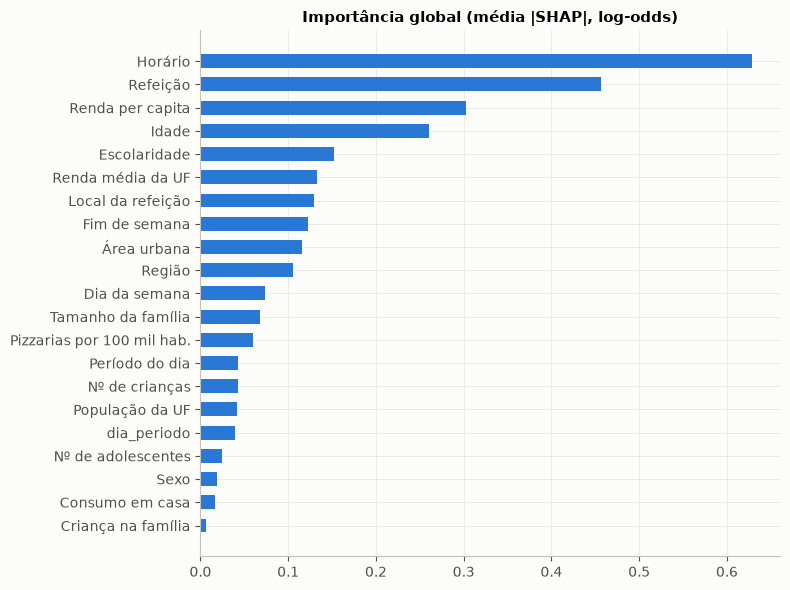

In [2]:
exp = Explicador(modelo)
amostra = base.sample(20000, random_state=SEED)
contrib = exp.contribuicoes(amostra)
imp = contrib.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([NOMES.get(c, c) for c in imp.index], imp.values, color=AZUL, height=0.6)
ax.set_title("Importância global (média |SHAP|, log-odds)")
plt.tight_layout()
plt.show()

### Direção dos efeitos
Para as variáveis numéricas mais importantes: valor da variável × contribuição SHAP.

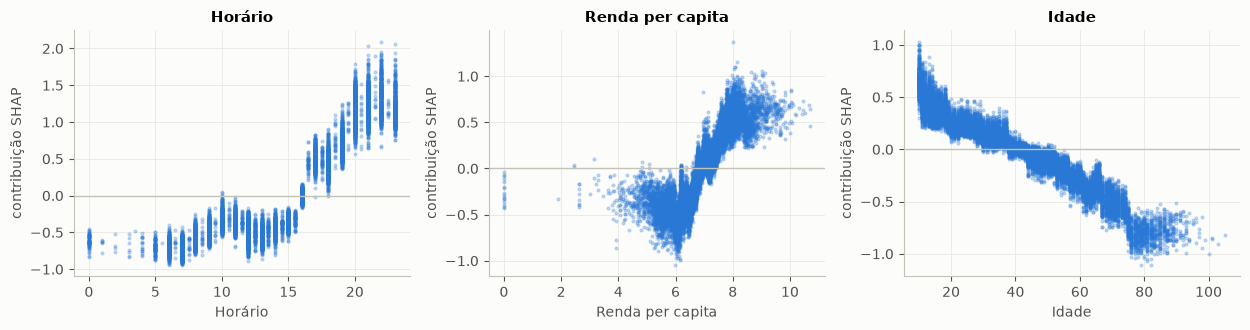

In [3]:
num_top = [c for c in imp.index[::-1] if pd.api.types.is_numeric_dtype(amostra[c]) and amostra[c].nunique() > 5][:3]
fig, axes = plt.subplots(1, len(num_top), figsize=(4.2 * len(num_top), 3.4))
for ax, c in zip(np.atleast_1d(axes), num_top):
    ax.scatter(amostra[c], contrib[c], s=4, alpha=0.25, color=AZUL)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_xlabel(NOMES.get(c, c))
    ax.set_ylabel("contribuição SHAP")
    ax.set_title(NOMES.get(c, c))
plt.tight_layout()
plt.show()

## 2. SHAP local — explicando uma previsão

Isso é o que a aplicação mostra em `top_factors` para cada contexto.

In [4]:
exemplo = base.sort_values("score").iloc[[-50]]  # um contexto de score alto
cols_show = ["dia_semana", "periodo", "refeicao", "local", "idade", "renda_pc", "n_moradores", "tem_crianca", "regiao"]
display(exemplo[cols_show + ["score"]])
pd.DataFrame(exp.top_fatores(exemplo, n=5))

,dia_semana,periodo,refeicao,local,idade,renda_pc,n_moradores,tem_crianca,regiao,score
158529,Sexta-Feira,noite,jantar,restaurante,47,13344.058125,4,1,Nordeste,0.463101


,fator,variavel,valor,impacto,direcao
0,Local da refeição,local,restaurante,1.9194,aumenta
1,Horário,hora,21.0,1.8177,aumenta
2,Refeição,refeicao,jantar,1.4484,aumenta
3,Renda per capita,log_renda_pc,R$ 13.344,0.5228,aumenta
4,Escolaridade,anos_estudo,16,0.3485,aumenta


## 3. Jobs to be done: clusters das ocasiões de pizza

Aplicamos a lógica do artigo de segmentação (K-means) às **ocasiões que tiveram pizza**: queremos descobrir **tipos de ocasião** e lê-los como *jobs* ("jantar em família", "pizza fora com amigos"...).

Do artigo, aplicamos:
1. **Bases de segmentação**: comportamental/contexto (horário, fim de semana, em casa) + demográfica (idade, renda, família).
2. **Padronização** antes do K-means (o artigo não menciona, mas é obrigatório: o K-means usa distância, e renda em R$ dominaria tudo).
3. **Escolha do K** pelo cotovelo (inércia) — e acrescentamos a **silhueta**, porque o cotovelo às vezes não é claro.
4. **Perfil e nome** de cada cluster a partir dos centroides.

**Por que o cluster NÃO entra no modelo:** ele é usado pelo **Decision Engine** para escolher o tipo de ativação. Assim não há risco de vazamento e o papel de cada peça fica claro: **o modelo diz se a ocasião é provável; o cluster diz que tipo de ocasião é.**

Ocasiões de pizza para clusterizar: 1701


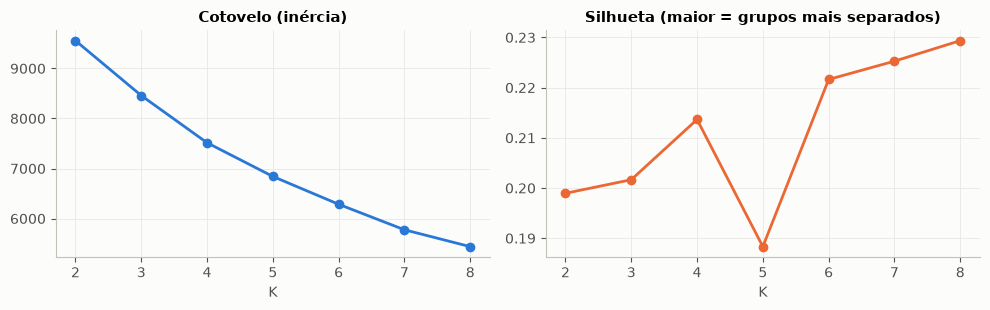

In [5]:
VARS_JOB = ["hora", "fim_de_semana", "em_casa", "n_moradores", "tem_crianca", "idade", "log_renda_pc"]
pz = base[base[TARGET] == 1].dropna(subset=VARS_JOB).reset_index(drop=True)
print("Ocasiões de pizza para clusterizar:", len(pz))

Xs = StandardScaler().fit_transform(pz[VARS_JOB])
ks = range(2, 9)
inercia, silh = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    inercia.append(km.inertia_)
    silh.append(silhouette_score(Xs, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(list(ks), inercia, marker="o", color=AZUL, lw=2)
axes[0].set_title("Cotovelo (inércia)")
axes[0].set_xlabel("K")
axes[1].plot(list(ks), silh, marker="o", color=LARANJA, lw=2)
axes[1].set_title("Silhueta (maior = grupos mais separados)")
axes[1].set_xlabel("K")
plt.tight_layout()
plt.show()

Escolhemos K entre 4 e 6 (número de jobs que o negócio consegue acionar) com a **melhor silhueta** nessa faixa.

In [6]:
K = int(max(range(4, 7), key=lambda k: silh[k - 2]))
print("K escolhido:", K)
kmeans_pipe = Pipeline([("escalar", StandardScaler()),
                        ("kmeans", KMeans(n_clusters=K, n_init=20, random_state=SEED))])
pz["cluster"] = kmeans_pipe.fit_predict(pz[VARS_JOB])

perfil = pz.groupby("cluster").agg(
    ocasioes=("hora", "size"), hora=("hora", "mean"), fim_de_semana=("fim_de_semana", "mean"),
    em_casa=("em_casa", "mean"), n_moradores=("n_moradores", "mean"), tem_crianca=("tem_crianca", "mean"),
    idade=("idade", "mean"), renda_pc=("renda_pc", "median"),
    attach_refri=("tem_refri", "mean"),
)
perfil["share_guarana"] = pz[pz.tem_refri == 1].groupby("cluster")["tem_guarana"].mean()
perfil.round(2)

K escolhido: 6


,ocasioes,hora,fim_de_semana,em_casa,n_moradores,tem_crianca,idade,renda_pc,attach_refri,share_guarana
cluster,,,,,,,,,,
0,370,20.02,1.00,1.00,3.16,0.02,37.51,1695.54,0.38,0.24
1,231,19.65,0.52,0.00,2.67,0.02,36.17,2187.75,0.40,0.19
2,136,9.78,0.44,0.77,3.15,0.32,32.23,1488.26,0.18,0.33
3,469,19.90,0.46,1.00,4.41,0.99,30.03,1174.78,0.39,0.38
4,283,19.84,0.00,1.00,2.78,0.02,40.78,2237.03,0.28,0.20
5,212,19.90,0.49,0.00,4.07,0.93,28.58,977.03,0.52,0.34


### Nomeando os clusters como jobs
Regras simples aplicadas ao perfil (documentadas para serem reproduzíveis). Ajuste os nomes se a leitura do perfil sugerir algo melhor.

In [7]:
def nomear(r):
    if r.em_casa < 0.5:
        return "Pizza fora com a família" if r.tem_crianca >= 0.5 else "Pizza fora de casa (social)"
    if r.hora < 17:
        return "Pizza no lanche / refeição do dia"
    if r.tem_crianca >= 0.5:
        return "Jantar em família com crianças"
    if r.fim_de_semana >= 0.7:
        return "Noite de fim de semana em casa (adultos)"
    if r.fim_de_semana <= 0.3:
        return "Pizza em casa no meio da semana (adultos)"
    return "Noite em casa (adultos)"


med = pz["renda_pc"].median()
nomes = {}
for c, r in perfil.iterrows():
    n = nomear(r)
    while n in nomes.values():
        n += " (2)"
    nomes[c] = n
perfil.insert(0, "job", pd.Series(nomes))
perfil.style.format({"hora": "{:.1f}", "fim_de_semana": "{:.0%}", "em_casa": "{:.0%}", "n_moradores": "{:.1f}",
                     "tem_crianca": "{:.0%}", "idade": "{:.0f}", "renda_pc": "R$ {:,.0f}",
                     "attach_refri": "{:.0%}", "share_guarana": "{:.0%}"})

,job,ocasioes,hora,fim_de_semana,em_casa,n_moradores,tem_crianca,idade,renda_pc,attach_refri,share_guarana
cluster,,,,,,,,,,,
0,Noite de fim de semana em casa (adultos),370,20.0,100%,100%,3.2,2%,38,"R$ 1,696",38%,24%
1,Pizza fora de casa (social),231,19.7,52%,0%,2.7,2%,36,"R$ 2,188",40%,19%
2,Pizza no lanche / refeição do dia,136,9.8,44%,77%,3.2,32%,32,"R$ 1,488",18%,33%
3,Jantar em família com crianças,469,19.9,46%,100%,4.4,99%,30,"R$ 1,175",39%,38%
4,Pizza em casa no meio da semana (adultos),283,19.8,0%,100%,2.8,2%,41,"R$ 2,237",28%,20%
5,Pizza fora com a família,212,19.9,49%,0%,4.1,93%,29,R$ 977,52%,34%


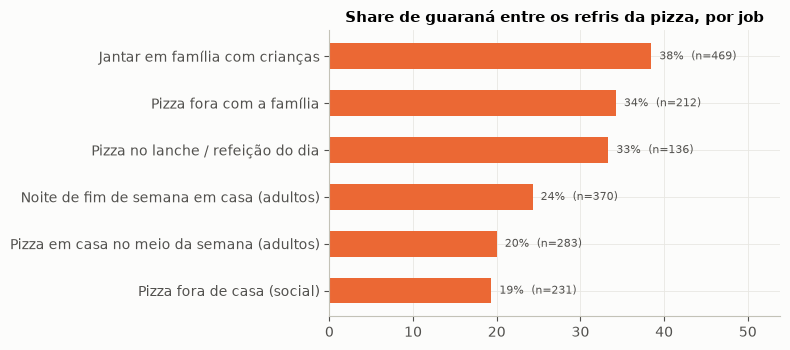

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
p = perfil.sort_values("share_guarana")
ax.barh(p["job"], p["share_guarana"] * 100, color=LARANJA, height=0.55)
for i, (v, n) in enumerate(zip(p["share_guarana"] * 100, p["ocasioes"])):
    ax.text(v, i, f"  {v:.0f}%  (n={n})", va="center", fontsize=8, color=CINZA)
ax.set_title("Share de guaraná entre os refris da pizza, por job")
ax.set_xlim(0, p["share_guarana"].max() * 140)
plt.tight_layout()
plt.show()

## 4. Métricas de Guaraná por segmento (região × classe de renda)

Com amostras pequenas, uma célula com 8 casos pode mostrar 0% ou 60% por acaso. Usamos **suavização**: puxamos a taxa do segmento em direção à média Brasil, com força equivalente a 20 observações.
`taxa_suavizada = (positivos + 20 × média_Brasil) / (n + 20)`

In [10]:
K_SUAV = 20
pzall = base[base[TARGET] == 1]
attach_br = pzall["tem_refri"].mean()
share_br = pzall.loc[pzall.tem_refri == 1, "tem_guarana"].mean()

def suavizar(pos, n, media):
    return (pos + K_SUAV * media) / (n + K_SUAV)

seg = []
for (reg, cls), g in pzall.groupby(["regiao", "classe_renda"], observed=True):
    gr = g[g.tem_refri == 1]
    seg.append({"regiao": reg, "classe_renda": str(cls), "n_pizza": len(g), "n_pizza_refri": len(gr),
                "attach_refri": suavizar(g.tem_refri.sum(), len(g), attach_br),
                "share_guarana": suavizar(gr.tem_guarana.sum(), len(gr), share_br)})
seg = pd.DataFrame(seg)
print(f"Brasil — attach: {attach_br:.1%} | share guaraná: {share_br:.1%}")
seg.pivot(index="regiao", columns="classe_renda", values="share_guarana").style.format("{:.0%}").background_gradient(cmap="Oranges")

Brasil — attach: 37.0% | share guaraná: 29.2%


classe_renda,A,B,C,D,E
regiao,,,,,
Centro-Oeste,27%,29%,37%,31%,28%
Nordeste,21%,33%,39%,25%,23%
Norte,25%,19%,33%,28%,29%
Sudeste,22%,38%,43%,31%,30%
Sul,22%,19%,37%,35%,34%


## 5. Mapa de Oportunidade por UF (regra documentada, não um novo modelo)

Para cada UF:
- `lift_medio`: média ponderada do Occasion Score das ocasiões da UF ÷ taxa base Brasil → **quanto a ocasião acontece ali**;
- `share_guarana_regiao`: share de guaraná suavizado da região da UF → **quanto o Guaraná já está**;
- **`potencial = lift_medio × (share_Brasil ÷ share_região)`** → alto quando há muita pizza **e** pouco guaraná.

A UF herda o share da região porque, por UF, há pizzas com refrigerante demais poucas para um número confiável.
O canal sugerido segue a mesma lógica do Decision Engine: muitas pizzarias por habitante → delivery/ponto de consumo; poucas → combo para casa.

In [11]:
taxa_base = meta["taxa_base"]
reg = {}
for r_, g in pzall.groupby("regiao"):
    gr = g[g.tem_refri == 1]
    reg[r_] = suavizar(gr.tem_guarana.sum(), len(gr), share_br)
ufs = (base.groupby(["uf", "sigla", "regiao"])
       .apply(lambda g: pd.Series({"lift_medio": np.average(g.score, weights=g.peso) / taxa_base,
                                    "pizzarias_100k": g.pizzarias_100k.iat[0]}), include_groups=False)
       .reset_index())
ufs["share_guarana_regiao"] = ufs["regiao"].map(reg)
ufs["potencial"] = ufs["lift_medio"] * (share_br / ufs["share_guarana_regiao"])
med_pizz = ufs["pizzarias_100k"].median()
ufs["canal_sugerido"] = np.where(ufs["pizzarias_100k"] >= med_pizz, "Delivery / ponto de consumo", "Combo para casa (varejo)")
ufs = ufs.sort_values("potencial", ascending=False).reset_index(drop=True)
ufs["ranking"] = ufs.index + 1
ufs.style.format({"lift_medio": "{:.2f}×", "pizzarias_100k": "{:.1f}", "share_guarana_regiao": "{:.0%}", "potencial": "{:.2f}"})

,uf,sigla,regiao,lift_medio,pizzarias_100k,share_guarana_regiao,potencial,canal_sugerido,ranking
0,43,RS,Sul,2.06×,3.2,26%,2.29,Delivery / ponto de consumo,1
1,53,DF,Centro-Oeste,2.46×,6.4,32%,2.28,Delivery / ponto de consumo,2
2,42,SC,Sul,1.65×,4.8,26%,1.84,Delivery / ponto de consumo,3
3,41,PR,Sul,1.58×,2.6,26%,1.76,Delivery / ponto de consumo,4
4,14,RR,Norte,1.45×,5.6,26%,1.66,Delivery / ponto de consumo,5
5,35,SP,Sudeste,1.56×,2.8,34%,1.33,Delivery / ponto de consumo,6
6,50,MS,Centro-Oeste,1.42×,1.2,32%,1.32,Combo para casa (varejo),7
7,52,GO,Centro-Oeste,1.40×,1.0,32%,1.29,Combo para casa (varejo),8
8,16,AP,Norte,1.12×,2.2,26%,1.28,Delivery / ponto de consumo,9
9,33,RJ,Sudeste,1.47×,2.4,34%,1.26,Delivery / ponto de consumo,10


## 6. Salvar os artefatos para a API

In [12]:
joblib.dump({"pipeline": kmeans_pipe, "variaveis": VARS_JOB, "nomes": {int(k): v for k, v in nomes.items()}},
            ROOT / "models" / "jobs_kmeans.joblib")

limites_renda = base.groupby("classe_renda", observed=True)["renda_pc"].agg(["min", "max"])
artefato = {
    "brasil": {"attach_refri": float(attach_br), "share_guarana": float(share_br)},
    "segmentos": seg.to_dict(orient="records"),
    "jobs": [{"cluster": int(c), "job": r.job, "ocasioes": int(r.ocasioes),
              "attach_refri": float(r.attach_refri), "share_guarana": float(r.share_guarana)}
             for c, r in perfil.iterrows()],
    "ufs": ufs.to_dict(orient="records"),
    "classe_renda_limites": {str(k): [float(v["min"]), float(v["max"])] for k, v in limites_renda.iterrows()},
}
(ROOT / "models" / "segmentos.json").write_text(json.dumps(artefato, indent=2, ensure_ascii=False), encoding="utf-8")
print("ok")

ok


## 7. Decision Engine em ação

As regras estão em `src/decision_engine.py` (R1 a R6, documentadas no topo do arquivo). Testamos com três contextos reais da base: score alto, médio e baixo.

In [13]:
seg_idx = seg.set_index(["regiao", "classe_renda"])
taxa_base, limiar_alta = meta["taxa_base"], meta["limiar_alta"]

def recomendar(linha: pd.DataFrame):
    r = linha.iloc[0]
    p = float(modelo.predict_proba(linha)[:, 1][0])
    classe = "alta" if p >= limiar_alta else ("media" if p >= taxa_base else "baixa")
    s = seg_idx.loc[(r.regiao, str(r.classe_renda))]
    # o job só faz sentido se a ocasião de pizza é provável (os clusters foram feitos só com ocasiões de pizza)
    job = nomes[int(kmeans_pipe.predict(linha[VARS_JOB])[0])] if classe != "baixa" else None
    e = Entrada(occasion_score=p, classificacao=classe, lift=p / taxa_base, em_casa=bool(r.em_casa),
                fim_de_semana=bool(r.fim_de_semana), attach_refri_segmento=s.attach_refri,
                share_guarana_segmento=s.share_guarana, attach_refri_brasil=attach_br,
                share_guarana_brasil=share_br, job=job, top_fatores=exp.top_fatores(linha))
    return {"occasion_score": round(p, 4), "classificacao": classe, **decidir(e)}

ordenada = base.dropna(subset=VARS_JOB + ["classe_renda"]).sort_values("score")
for pos in [-30, int(len(ordenada) * 0.93), 100]:
    linha = ordenada.iloc[[pos]]
    print(linha[cols_show].to_dict("records")[0])
    out = recomendar(linha)
    print(f"→ score {out['occasion_score']:.2%} ({out['classificacao']}) | {out['recommendation_label']}")
    print("  ", out["recommendation_reason"], "\n")

{'dia_semana': 'Terca-Feira', 'periodo': 'noite', 'refeicao': 'jantar', 'local': 'restaurante', 'idade': 13, 'renda_pc': 1789.1486666667, 'n_moradores': 5, 'tem_crianca': 1, 'regiao': 'Nordeste'}
→ score 50.41% (alta) | Ativação no ponto de consumo (pizzaria/restaurante)
   Score alto (lift 103.1×) com consumo fora de casa: a decisão do refrigerante acontece na pizzaria/restaurante. Principais fatores do score: Local da refeição (aumenta), Horário (aumenta), Refeição (aumenta). Job provável: Pizza fora com a família. 

{'dia_semana': 'Quinta-Feira', 'periodo': 'tarde', 'refeicao': 'lanche', 'local': 'casa', 'idade': 53, 'renda_pc': 3117.3733333333, 'n_moradores': 3, 'tem_crianca': 0, 'regiao': 'Sul'}
→ score 1.51% (alta) | Combo / promoção para consumo em casa
   No segmento, só 27% das pizzas vêm com refrigerante (Brasil: 37%): espaço para combo pizza + Guaraná. Principais fatores do score: Renda per capita (aumenta), Horário (aumenta), Refeição (aumenta). Job provável: Pizza em casa 

## Resumo

- **SHAP** mostra os fatores que mais movem o score; a aplicação exibe os 4 principais de cada previsão.
- **Jobs:** K-means nas ocasiões de pizza, nomeados pelo perfil. Cada job tem attach e share de guaraná próprios → indica que tipo de ocasião tem mais espaço para o Guaraná.
- **Segmentos:** métricas de Guaraná por região × classe, suavizadas para amostras pequenas.
- **Decision Engine:** regras R1–R6 combinam score + contexto + métricas de marca → categoria de ativação com justificativa.
- **Artefatos salvos** em `models/`: `occasion_model.joblib`, `metadata.json`, `jobs_kmeans.joblib`, `segmentos.json` → usados pela API.